In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MaxAbsScaler
from sklearn.pipeline import make_pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [2]:
df = pd.read_csv("emails.csv")

print("Dataset Shape:", df.shape)
print("\nFirst 5 rows:")
display(df.head())

print("\nMissing Values:", df.isnull().sum().sum())
print("\nColumn Names:")
print(df.columns)

Dataset Shape: (5172, 3002)

First 5 rows:


,Email No.,the,to,ect,and,for,of,a,you,hou,...,connevey,jay,valued,lay,infrastructure,military,allowing,ff,dry,Prediction
0,Email 1,0,0,1,0,0,0,2,0,0,...,0,0,0,0,0,0,0,0,0,0
1,Email 2,8,13,24,6,6,2,102,1,27,...,0,0,0,0,0,0,0,1,0,0
2,Email 3,0,0,1,0,0,0,8,0,0,...,0,0,0,0,0,0,0,0,0,0
3,Email 4,0,5,22,0,5,1,51,2,10,...,0,0,0,0,0,0,0,0,0,0
4,Email 5,7,6,17,1,5,2,57,0,9,...,0,0,0,0,0,0,0,1,0,0



Missing Values: 0

Column Names:
Index(['Email No.', 'the', 'to', 'ect', 'and', 'for', 'of', 'a', 'you', 'hou',
       ...
       'connevey', 'jay', 'valued', 'lay', 'infrastructure', 'military',
       'allowing', 'ff', 'dry', 'Prediction'],
      dtype='str', length=3002)


In [3]:
# Remove duplicate rows
df = df.drop_duplicates()

# Fill missing values in numeric columns
df = df.fillna(0)

# Separate features and target
X = df.iloc[:, 1:-1]
y = df.iloc[:, -1].astype(int)

print("Features Shape:", X.shape)
print("\nClass Distribution:")
print(y.value_counts())

print("\n0 = Not Spam")
print("1 = Spam")

Features Shape: (5172, 3000)

Class Distribution:
Prediction
0    3672
1    1500
Name: count, dtype: int64

0 = Not Spam
1 = Spam


In [4]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (4137, 3000)
Testing Data: (1035, 3000)


In [5]:
knn_model = make_pipeline(
    MaxAbsScaler(),
    KNeighborsClassifier(n_neighbors=5)
)

knn_model.fit(X_train, y_train)

knn_pred = knn_model.predict(X_test)

print("KNN Classification Report:")
print(classification_report(
    y_test, knn_pred,
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

KNN Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.97      0.84      0.90       735
        Spam       0.70      0.94      0.81       300

    accuracy                           0.87      1035
   macro avg       0.84      0.89      0.85      1035
weighted avg       0.89      0.87      0.87      1035



In [6]:
svm_model = make_pipeline(
    MaxAbsScaler(),
    SVC(kernel="linear", C=1.0)
)

svm_model.fit(X_train, y_train)

svm_pred = svm_model.predict(X_test)

print("SVM Classification Report:")
print(classification_report(
    y_test, svm_pred,
    target_names=["Not Spam", "Spam"],
    zero_division=0
))

SVM Classification Report:
              precision    recall  f1-score   support

    Not Spam       0.99      0.97      0.98       735
        Spam       0.92      0.98      0.95       300

    accuracy                           0.97      1035
   macro avg       0.96      0.97      0.96      1035
weighted avg       0.97      0.97      0.97      1035



In [7]:
models = {
    "KNN": knn_pred,
    "SVM": svm_pred
}

results = []

for name, pred in models.items():
    results.append({
        "Model": name,
        "Accuracy (%)": round(
            accuracy_score(y_test, pred) * 100, 2
        ),
        "Precision (%)": round(
            precision_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "Recall (%)": round(
            recall_score(y_test, pred, zero_division=0) * 100, 2
        ),
        "F1-Score (%)": round(
            f1_score(y_test, pred, zero_division=0) * 100, 2
        )
    })

results_df = pd.DataFrame(results)
display(results_df)

best_model = results_df.loc[
    results_df["F1-Score (%)"].idxmax(), "Model"
]

print("Best Model based on F1-score:", best_model)

,Model,Accuracy (%),Precision (%),Recall (%),F1-Score (%)
0,KNN,86.76,70.22,94.33,80.51
1,SVM,97.00,92.16,98.00,94.99


Best Model based on F1-score: SVM


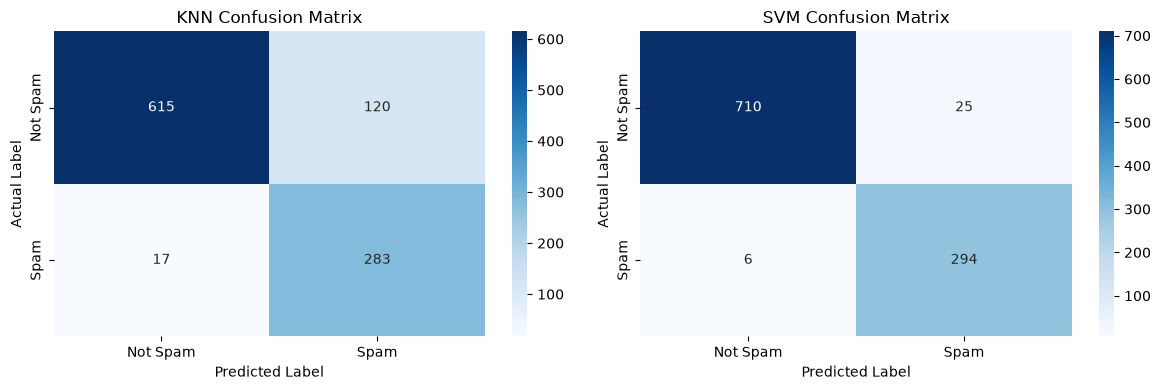

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, (name, pred) in zip(axes, models.items()):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=["Not Spam", "Spam"],
        yticklabels=["Not Spam", "Spam"],
        ax=ax
    )

    ax.set_title(name + " Confusion Matrix")
    ax.set_xlabel("Predicted Label")
    ax.set_ylabel("Actual Label")

plt.tight_layout()
plt.show()

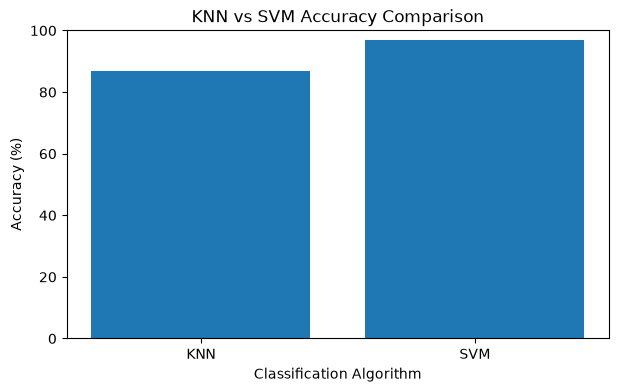

In [9]:
plt.figure(figsize=(7, 4))

plt.bar(
    results_df["Model"],
    results_df["Accuracy (%)"]
)

plt.title("KNN vs SVM Accuracy Comparison")
plt.xlabel("Classification Algorithm")
plt.ylabel("Accuracy (%)")
plt.ylim(0, 100)

plt.show()